**Lab 5—Logistic Regression on Titanic Dataset**

Instructor Name: Attique-ur-Rehman

Student Name: Fatima Kashif

Sap Id: 70177832


In [1]:
!pip install numpy pandas scikit-learn matplotlib seaborn joblib

In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, pickle

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("figures", exist_ok=True)

In [3]:
URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df_raw = pd.read_csv("train.csv") if os.path.exists("train.csv") else pd.read_csv(URL)
print(df_raw.shape)
df_raw.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

Missing values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked    

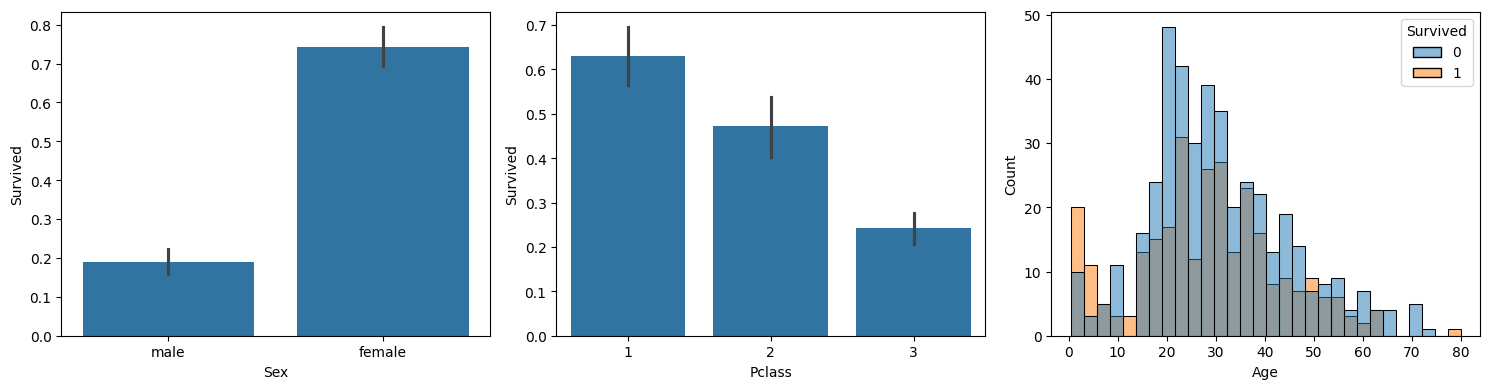

In [4]:
print(df_raw.info())
print("\nMissing values:\n", df_raw.isnull().sum())

print("\nClass balance:\n", df_raw["Survived"].value_counts(normalize=True).round(3))
baseline = 1 - df_raw["Survived"].mean()
print(f"\nBASELINE accuracy (always predict 'did not survive'): {baseline:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=df_raw, x="Sex", y="Survived", ax=ax[0])
sns.barplot(data=df_raw, x="Pclass", y="Survived", ax=ax[1])
sns.histplot(data=df_raw, x="Age", hue="Survived", bins=30, ax=ax[2])
plt.tight_layout(); plt.show()

In [5]:
df = df_raw.copy()
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

FEATURES = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "FamilySize", "IsAlone"]
X = df[FEATURES].copy()
y = df["Survived"].copy()

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print(X_train.shape, X_test.shape)
print("Train survival rate:", round(y_train.mean(), 3), "| Test:", round(y_test.mean(), 3))

(712, 9) (179, 9)
Train survival rate: 0.383 | Test: 0.385


In [7]:
age_median   = X_train["Age"].median()
fare_median  = X_train["Fare"].median()
embarked_mode = X_train["Embarked"].mode()[0]

def impute(d):
    d = d.copy()
    d["Age"]      = d["Age"].fillna(age_median)
    d["Fare"]     = d["Fare"].fillna(fare_median)
    d["Embarked"] = d["Embarked"].fillna(embarked_mode)
    return d

X_train = impute(X_train)
X_test  = impute(X_test)
print("Remaining nulls:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())

Remaining nulls: 0 0


In [8]:
encoders = {}
for col in ["Sex", "Embarked"]:
    le = LabelEncoder().fit(X_train[col])
    X_train[col] = le.transform(X_train[col])
    X_test[col]  = le.transform(X_test[col])
    encoders[col] = le
    with open(f"{col.lower()}_encoder.pkl", "wb") as f:
        pickle.dump(le, f)

print({c: list(e.classes_) for c, e in encoders.items()})
X_train.head()

{'Sex': ['female', 'male'], 'Embarked': ['C', 'Q', 'S']}


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone
692,3,1,28.5,0,0,56.4958,2,1,1
481,2,1,28.5,0,0,0.0000,2,1,1
527,1,1,28.5,0,0,221.7792,2,1,1
855,3,0,18.0,0,1,9.3500,2,2,0
801,2,0,31.0,1,1,26.2500,2,3,0


In [9]:
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),      columns=X_test.columns,  index=X_test.index)

# Save preprocessing artefacts for Lab 6
joblib.dump({"age_median": age_median, "fare_median": fare_median,
             "embarked_mode": embarked_mode, "features": FEATURES},
            "preprocessing_values.joblib")
joblib.dump(scaler, "scaler.joblib")

['scaler.joblib']

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree":       DecisionTreeClassifier(random_state=SEED),
    "Random Forest":       RandomForestClassifier(random_state=SEED),
}

def compare(models, Xtr, Xte, ytr, yte):
    rows, fitted = [], {}
    for name, m in models.items():
        m.fit(Xtr, ytr)
        pred  = m.predict(Xte)
        proba = m.predict_proba(Xte)[:, 1]
        rows.append({"Model": name,
                     "Accuracy": accuracy_score(yte, pred),
                     "AUC": roc_auc_score(yte, proba)})
        fitted[name] = m
    return pd.DataFrame(rows).set_index("Model").round(4), fitted

results, fitted = compare(models, X_train_s, X_test_s, y_train, y_test)
print(f"Baseline: {baseline:.3f}")
results

Baseline: 0.616


,Accuracy,AUC
Model,,
Logistic Regression,0.8101,0.8586
Decision Tree,0.7765,0.7536
Random Forest,0.7989,0.8272


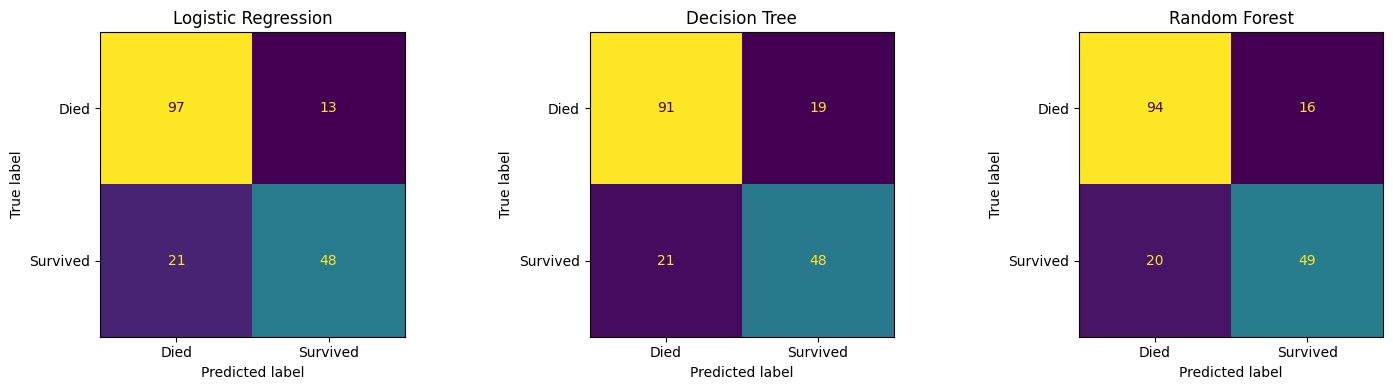


=== Logistic Regression ===
              precision    recall  f1-score   support

        Died       0.82      0.88      0.85       110
    Survived       0.79      0.70      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.81      0.81      0.81       179


=== Decision Tree ===
              precision    recall  f1-score   support

        Died       0.81      0.83      0.82       110
    Survived       0.72      0.70      0.71        69

    accuracy                           0.78       179
   macro avg       0.76      0.76      0.76       179
weighted avg       0.78      0.78      0.78       179


=== Random Forest ===
              precision    recall  f1-score   support

        Died       0.82      0.85      0.84       110
    Survived       0.75      0.71      0.73        69

    accuracy                           0.80       179
   macro avg       0.79      0.78      0.79       179

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, m) in zip(axes, fitted.items()):
    pred = m.predict(X_test_s)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Died", "Survived"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

for name, m in fitted.items():
    print(f"\n=== {name} ===")
    print(classification_report(y_test, m.predict(X_test_s), target_names=["Died", "Survived"]))

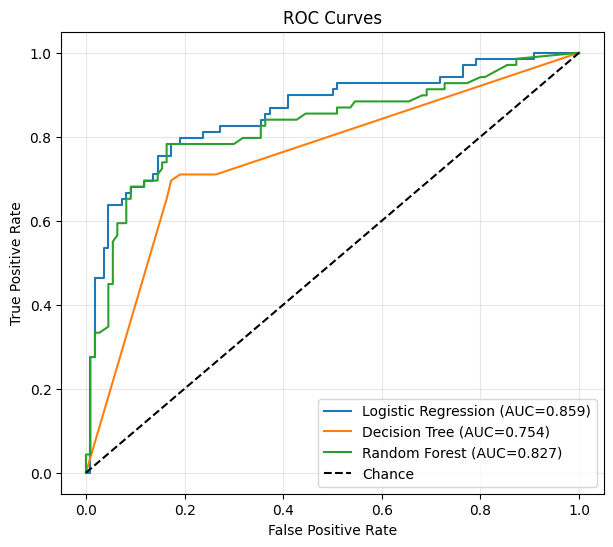

In [12]:
plt.figure(figsize=(7, 6))
for name, m in fitted.items():
    proba = m.predict_proba(X_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curves"); plt.legend(); plt.grid(alpha=.3)
plt.savefig("figures/roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
for name, m in models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", m)])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    cv_rows.append({"Model": name, "CV Mean": scores.mean(), "CV Std": scores.std()})
pd.DataFrame(cv_rows).set_index("Model").round(4)

,CV Mean,CV Std
Model,,
Logistic Regression,0.7978,0.0159
Decision Tree,0.7964,0.0112
Random Forest,0.7949,0.0196


In [14]:
base_cols = [c for c in X_train_s.columns if c not in ["FamilySize", "IsAlone"]]
res_without, _ = compare(models, X_train_s[base_cols], X_test_s[base_cols], y_train, y_test)

delta = pd.DataFrame({
    "With FamilySize/IsAlone":    results["Accuracy"],
    "Without FamilySize/IsAlone": res_without["Accuracy"],
})
delta["Delta (with - without)"] = delta.iloc[:, 0] - delta.iloc[:, 1]
delta.round(4)

,With FamilySize/IsAlone,Without FamilySize/IsAlone,Delta (with - without)
Model,,,
Logistic Regression,0.8101,0.7989,0.0112
Decision Tree,0.7765,0.8156,-0.0391
Random Forest,0.7989,0.8156,-0.0167


In [15]:
models_ext = {**models,
              "KNN": KNeighborsClassifier(),
              "SVC": SVC(probability=True, random_state=SEED)}
results_ext, fitted_ext = compare(models_ext, X_train_s, X_test_s, y_train, y_test)
results_ext.sort_values("Accuracy", ascending=False)

,Accuracy,AUC
Model,,
Logistic Regression,0.8101,0.8586
SVC,0.8101,0.8453
KNN,0.8101,0.8397
Random Forest,0.7989,0.8272
Decision Tree,0.7765,0.7536


In [17]:
param_grid = {
    "n_estimators":      [100, 200, 400],
    "max_depth":         [None, 4, 6, 8],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf":  [1, 2, 4],
}
grid = GridSearchCV(RandomForestClassifier(random_state=SEED),
                    param_grid, cv=cv, scoring="accuracy", n_jobs=-1)
grid.fit(X_train_s, y_train)

print("Best params:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.4f}")

best_model = grid.best_estimator_
test_pred = best_model.predict(X_test_s)
print(f"Test accuracy (tuned): {accuracy_score(y_test, test_pred):.4f}")
print(f"Test AUC (tuned):      {roc_auc_score(y_test, best_model.predict_proba(X_test_s)[:,1]):.4f}")

Best params: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}
Best CV accuracy: 0.8231
Test accuracy (tuned): 0.8101
Test AUC (tuned):      0.8366


In [18]:
joblib.dump(best_model, "titanic_best_model.joblib")
print(sorted(f for f in os.listdir(".") if f.endswith((".joblib", ".pkl"))))

['embarked_encoder.pkl', 'preprocessing_values.joblib', 'scaler.joblib', 'sex_encoder.pkl', 'titanic_best_model.joblib']


In [19]:
def predict_survival(pclass, sex, age, sibsp, parch, fare, embarked):
    model = joblib.load("titanic_best_model.joblib")
    scl   = joblib.load("scaler.joblib")
    prep  = joblib.load("preprocessing_values.joblib")
    enc   = {c: pickle.load(open(f"{c.lower()}_encoder.pkl", "rb")) for c in ["Sex", "Embarked"]}

    fam = sibsp + parch + 1
    row = pd.DataFrame([{
        "Pclass": pclass, "Sex": sex,
        "Age": age if age is not None else prep["age_median"],
        "SibSp": sibsp, "Parch": parch,
        "Fare": fare if fare is not None else prep["fare_median"],
        "Embarked": embarked or prep["embarked_mode"],
        "FamilySize": fam, "IsAlone": int(fam == 1),
    }])[prep["features"]]

    for c in ["Sex", "Embarked"]:
        row[c] = enc[c].transform(row[c])
    row_s = scl.transform(row)

    p = model.predict_proba(row_s)[0, 1]
    return {"prediction": "SURVIVED" if p >= 0.5 else "NOT SURVIVED",
            "probability": round(float(p), 3)}

print(predict_survival(pclass=1, sex="female", age=29, sibsp=0, parch=0, fare=80, embarked="S"))
print(predict_survival(pclass=3, sex="male",   age=25, sibsp=0, parch=0, fare=7.5, embarked="S"))

{'prediction': 'SURVIVED', 'probability': 0.978}
{'prediction': 'NOT SURVIVED', 'probability': 0.035}


In [20]:
summary = results_ext.join(
    pd.DataFrame(cv_rows).set_index("Model"), how="left").sort_values("Accuracy", ascending=False)
summary.loc["Tuned Random Forest", ["Accuracy", "AUC"]] = [
    accuracy_score(y_test, test_pred),
    roc_auc_score(y_test, best_model.predict_proba(X_test_s)[:, 1])]
print(f"Baseline accuracy: {baseline:.3f}")
summary.round(4)

Baseline accuracy: 0.616


,Accuracy,AUC,CV Mean,CV Std
Model,,,,
Logistic Regression,0.8101,0.8586,0.7978,0.0159
SVC,0.8101,0.8453,NaN,NaN
KNN,0.8101,0.8397,NaN,NaN
Random Forest,0.7989,0.8272,0.7949,0.0196
Decision Tree,0.7765,0.7536,0.7964,0.0112
Tuned Random Forest,0.8101,0.8366,NaN,NaN
